In [2]:
import json
import os

from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from PIL import Image

from tqdm import tqdm

# notebook inline
%matplotlib inline

In [3]:
ANNOTATION_DIR = "./annotations"
IMAGE_DIR      = "./images"

SUPPORTED_EXTENSIONS = [".jpg", ".jpeg", ".png", ".webp"]

In [4]:
rows = []

json_files = sorted(Path(ANNOTATION_DIR).glob("*.json"))

print(f"Found {len(json_files)} annotation files")

for json_path in tqdm(json_files):

    try:
        with open(json_path, "r", encoding="utf-8") as f:
            data = json.load(f)

        stem = json_path.stem

        # 이미지 파일 찾기
        image_path = None

        for ext in SUPPORTED_EXTENSIONS:
            candidate = Path(IMAGE_DIR) / f"{stem}{ext}"

            if candidate.exists():
                image_path = str(candidate)
                break

        row = {
            "id": stem,
            "image_path": image_path,

            # top-level
            "num_people": data["num_people"],

            # scene
            "background": data["scene"]["background"],
            "lighting": ",".join(data["scene"]["lighting"]),
            "image_quality": ",".join(data["scene"]["image_quality"]),

            # person
            "pose": data["person"]["pose"],
            "yaw": data["person"]["yaw"],
            "pitch": data["person"]["pitch"],

            # mask
            "mask_state": data["mask"]["state"],
            "mask_type": data["mask"]["type"],
            "boundary_quality": data["mask"]["boundary_quality"],
            "deformation": data["mask"]["deformation"],

            # occlusion
            "occlusion_types": ",".join(data["occlusion"]["types"]),
            "hand_overlap_ratio": data["occlusion"]["hand_overlap_ratio"],
            "hair_overlap_ratio": data["occlusion"]["hair_overlap_ratio"],

            # visibility
            "mask_visible_ratio": data["visibility"]["mask_visible_ratio"],
            "nose_visible_ratio": data["visibility"]["nose_visible_ratio"],
            "mouth_visible_ratio": data["visibility"]["mouth_visible_ratio"],
            "chin_visible_ratio": data["visibility"]["chin_visible_ratio"],

            # difficulty
            "segmentation_difficulty": data["difficulty"]["segmentation_difficulty"],
            "difficulty_reasons": ",".join(data["difficulty"]["difficulty_reasons"]),
        }

        rows.append(row)

    except Exception as e:
        print(f"[ERROR] {json_path.name}: {e}")

df = pd.DataFrame(rows)

print(df.shape)

df.head()

Found 780 annotation files


100%|███████████████████████████████████████████████████████████████████████████████| 780/780 [00:02<00:00, 269.31it/s]

(780, 22)


,id,image_path,num_people,background,lighting,image_quality,pose,yaw,pitch,mask_state,...,deformation,occlusion_types,hand_overlap_ratio,hair_overlap_ratio,mask_visible_ratio,nose_visible_ratio,mouth_visible_ratio,chin_visible_ratio,segmentation_difficulty,difficulty_reasons
0,image_0_jpg.rf.63883eab24128937a067d97ebe735536,images\image_0_jpg.rf.63883eab24128937a067d97e...,1,crowd,"bright,uneven","medium,compressed",left,-18.0,0.0,normal,...,True,none,0.00,0.00,0.96,0.00,0.00,0.08,0.31,"deformation,low_contrast"
1,image_1001_jpg.rf.a8292e4128f58f4ea51728cd35d7...,images\image_1001_jpg.rf.a8292e4128f58f4ea5172...,1,outdoor,"bright,uneven",high,left,-24.0,4.0,mouth_exposed,...,True,"hair,hand,clothing",0.02,0.08,0.92,0.78,0.35,0.04,0.71,"deformation,ambiguous_boundary,partial_visibility"
2,image_1002_jpg.rf.0ccb96ea4df631eaeffd70e7965c...,images\image_1002_jpg.rf.0ccb96ea4df631eaeffd7...,1,vehicle,"bright,uneven,backlit","medium,blurry",front,8.0,-6.0,normal,...,False,"hand,hair",0.08,0.12,0.93,0.00,0.00,0.18,0.52,"hair_overlap,motion_blur,shadow"
3,image_1004_jpg.rf.b98d60be0171f473974a1a353368...,images\image_1004_jpg.rf.b98d60be0171f473974a1...,1,outdoor,"bright,warm",high,front,8.0,0.0,normal,...,False,none,0.00,0.00,0.96,0.00,0.00,0.00,0.18,
4,image_1005_jpg.rf.540a8cc793ff65fe7660e0b19dff...,images\image_1005_jpg.rf.540a8cc793ff65fe7660e...,1,plain,bright,high,profile_right,32.0,0.0,normal,...,False,hair,0.00,0.06,0.93,0.00,0.00,0.00,0.18,


## 기본 통계 확인

In [5]:
df.describe(include="all")

,id,image_path,num_people,background,lighting,image_quality,pose,yaw,pitch,mask_state,...,deformation,occlusion_types,hand_overlap_ratio,hair_overlap_ratio,mask_visible_ratio,nose_visible_ratio,mouth_visible_ratio,chin_visible_ratio,segmentation_difficulty,difficulty_reasons
count,780,780,780.000000,780,780,780,780,780.000000,780.000000,780,...,780,780,780.000000,780.000000,780.000000,780.000000,780.000000,780.000000,780.000000,780
unique,780,780,NaN,7,36,12,8,NaN,NaN,9,...,2,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN,184
top,image_0_jpg.rf.63883eab24128937a067d97ebe735536,images\image_0_jpg.rf.63883eab24128937a067d97e...,NaN,indoor,"bright,warm",medium,front,NaN,NaN,normal,...,True,none,NaN,NaN,NaN,NaN,NaN,NaN,NaN,deformation
freq,1,1,NaN,354,167,331,419,NaN,NaN,697,...,492,273,NaN,NaN,NaN,NaN,NaN,NaN,NaN,133
mean,NaN,NaN,1.275641,NaN,NaN,NaN,NaN,-0.100000,-1.141026,NaN,...,NaN,NaN,0.030692,0.067218,0.907269,0.046256,0.019410,0.044295,0.401526,NaN
std,NaN,NaN,0.921667,NaN,NaN,NaN,NaN,22.758547,6.810707,NaN,...,NaN,NaN,0.074552,0.076604,0.097905,0.182031,0.119617,0.111483,0.170206,NaN
min,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,-88.000000,-65.000000,NaN,...,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.120000,NaN
25%,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,-8.000000,-3.000000,NaN,...,NaN,NaN,0.000000,0.000000,0.900000,0.000000,0.000000,0.000000,0.280000,NaN
50%,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,1.000000,0.000000,NaN,...,NaN,NaN,0.000000,0.080000,0.930000,0.000000,0.000000,0.000000,0.350000,NaN
75%,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,8.000000,0.000000,NaN,...,NaN,NaN,0.000000,0.120000,0.960000,0.000000,0.000000,0.080000,0.460000,NaN


## Mask State 분포

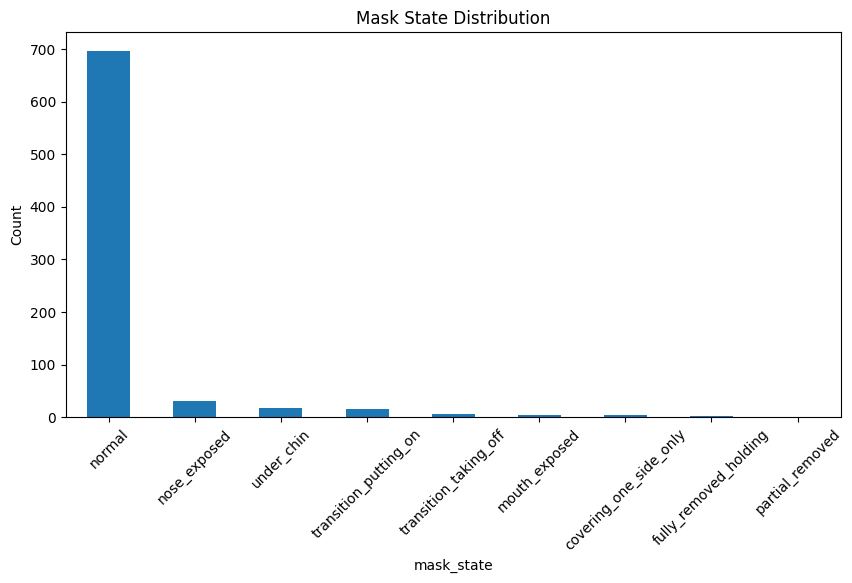

mask_state
normal                    697
nose_exposed               31
under_chin                 18
transition_putting_on      15
transition_taking_off       6
mouth_exposed               5
covering_one_side_only      4
fully_removed_holding       3
partial_removed             1
Name: count, dtype: int64


In [7]:
state_counts = df["mask_state"].value_counts()

plt.figure(figsize=(10, 5))

state_counts.plot(kind="bar")

plt.title("Mask State Distribution")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()

print(state_counts)

## Segmentation Difficulty 분포

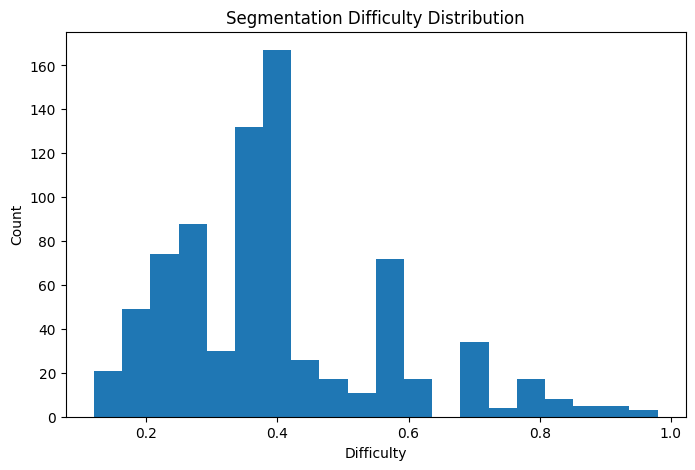

In [8]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["segmentation_difficulty"],
    bins=20
)

plt.title("Segmentation Difficulty Distribution")
plt.xlabel("Difficulty")
plt.ylabel("Count")

plt.show()

## Pose Distribution Scatter

매우 중요합니다.

정면 bias 확인 가능.

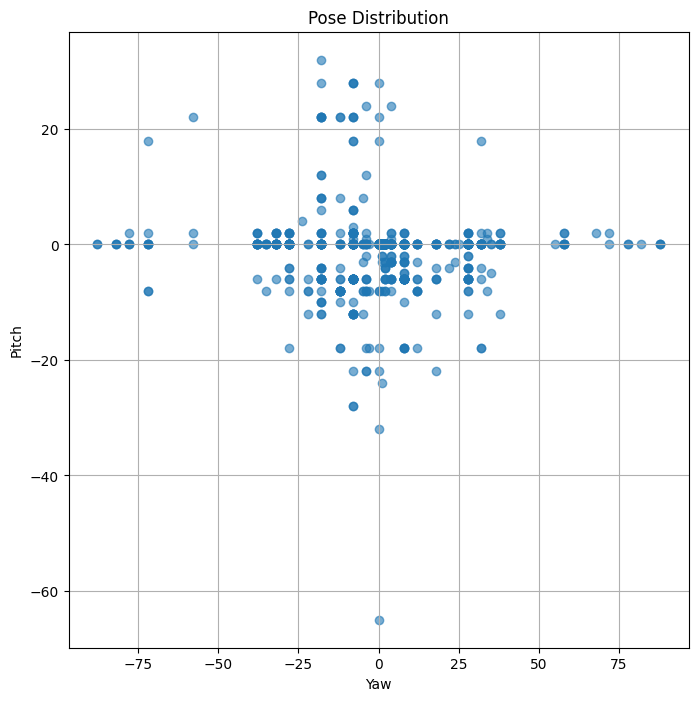

In [9]:
plt.figure(figsize=(8, 8))

plt.scatter(
    df["yaw"],
    df["pitch"],
    alpha=0.6
)

plt.xlabel("Yaw")
plt.ylabel("Pitch")

plt.title("Pose Distribution")

plt.grid(True)

plt.show()

## Visibility vs Difficulty

정상 데이터라면:

- visible ratio ↓
- difficulty ↑

경향이 나와야 합니다.

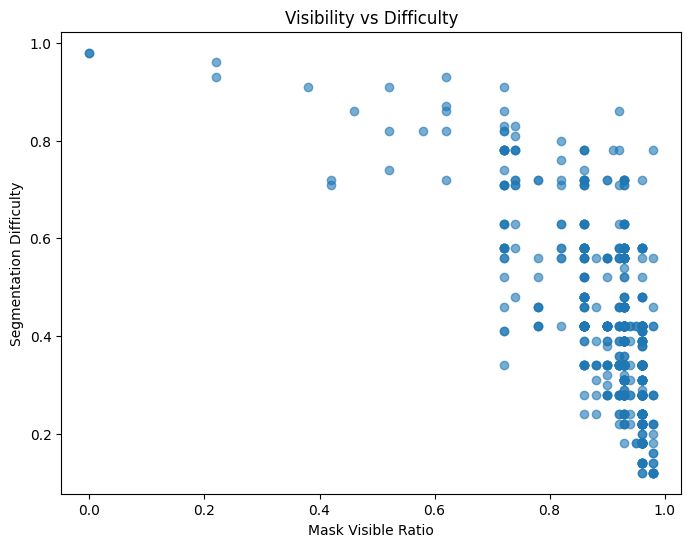

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["mask_visible_ratio"],
    df["segmentation_difficulty"],
    alpha=0.6
)

plt.xlabel("Mask Visible Ratio")
plt.ylabel("Segmentation Difficulty")

plt.title("Visibility vs Difficulty")

plt.show()

## Difficulty Reason 분석

edge-case coverage 핵심.

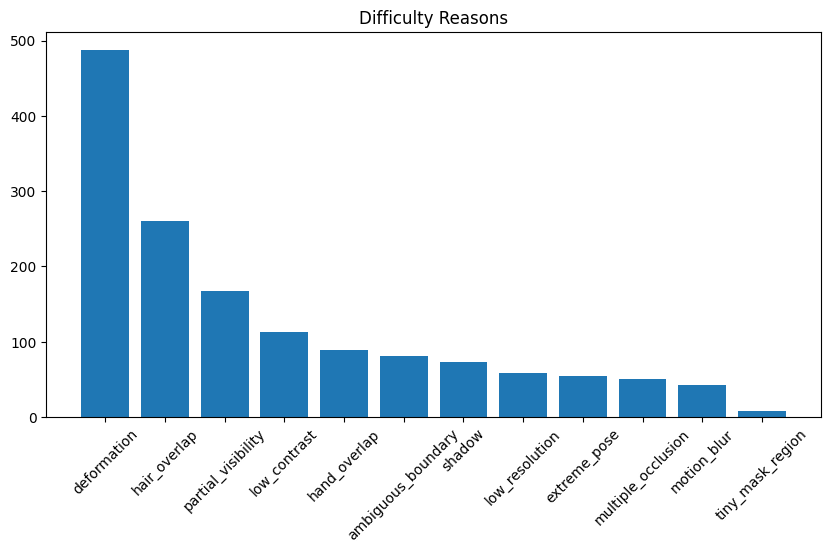

,reason,count
0,deformation,487
4,hair_overlap,260
3,partial_visibility,168
1,low_contrast,113
7,hand_overlap,89
2,ambiguous_boundary,81
6,shadow,73
8,low_resolution,58
10,extreme_pose,55
9,multiple_occlusion,51


In [11]:
from collections import Counter

counter = Counter()

for reasons in df["difficulty_reasons"]:
    for r in reasons.split(","):
        r = r.strip()

        if r:
            counter[r] += 1

reason_df = pd.DataFrame({
    "reason": list(counter.keys()),
    "count": list(counter.values())
})

reason_df = reason_df.sort_values(
    by="count",
    ascending=False
)

plt.figure(figsize=(10, 5))

plt.bar(
    reason_df["reason"],
    reason_df["count"]
)

plt.xticks(rotation=45)

plt.title("Difficulty Reasons")

plt.show()

reason_df

## Hard Sample Top-K 추출

실제 중요한 단계.

In [12]:
hard_df = df.sort_values(
    by="segmentation_difficulty",
    ascending=False
)

hard_df.head(20)

,id,image_path,num_people,background,lighting,image_quality,pose,yaw,pitch,mask_state,...,deformation,occlusion_types,hand_overlap_ratio,hair_overlap_ratio,mask_visible_ratio,nose_visible_ratio,mouth_visible_ratio,chin_visible_ratio,segmentation_difficulty,difficulty_reasons
636,image_1884_jpg.rf.298a59e6b74ac293ab4e4f098e61...,images\image_1884_jpg.rf.298a59e6b74ac293ab4e4...,1,indoor,dim,medium,front,0.0,0.0,fully_removed_holding,...,False,"hand,hair,object",0.12,0.08,0.00,0.00,0.00,0.00,0.98,"partial_visibility,multiple_occlusion,ambiguou..."
239,image_1323_jpg.rf.260fbdedd9a6e3978cb86f127471...,images\image_1323_jpg.rf.260fbdedd9a6e3978cb86...,1,indoor,"dim,warm",medium,front,2.0,0.0,fully_removed_holding,...,False,"hand,object",0.18,0.00,0.00,0.00,0.00,0.00,0.98,"partial_visibility,multiple_occlusion,ambiguou..."
713,image_1997_jpg.rf.092414655c5c7d29d253ba53bfd6...,images\image_1997_jpg.rf.092414655c5c7d29d253b...,4,complex,bright,medium,front,0.0,0.0,normal,...,False,none,0.00,0.00,0.22,0.78,0.52,0.55,0.96,"partial_visibility,multiple_occlusion,ambiguou..."
749,image_2040_jpg.rf.739559c3a23f1c4c41d528742d98...,images\image_2040_jpg.rf.739559c3a23f1c4c41d52...,1,outdoor,"dim,uneven","low,blurry,noisy",front,8.0,-6.0,normal,...,False,hair,0.00,0.14,0.62,0.00,0.00,0.08,0.93,"low_resolution,motion_blur,low_contrast,partia..."
613,image_1856_jpg.rf.349d1ab1cbf5be6aadcb5784c82f...,images\image_1856_jpg.rf.349d1ab1cbf5be6aadcb5...,7,indoor,"bright,uneven,backlit",medium,down,-8.0,28.0,normal,...,False,hair,0.00,0.62,0.22,0.00,0.00,0.00,0.93,"hair_overlap,extreme_pose,partial_visibility,m..."
646,image_1894_jpg.rf.69d8bfc76912b378504c9b5e02cb...,images\image_1894_jpg.rf.69d8bfc76912b378504c9...,2,vehicle,"dim,uneven","low,blurry,compressed",front,8.0,0.0,transition_taking_off,...,True,"hand,hair,shadow",0.46,0.14,0.52,0.18,0.00,0.00,0.91,"hand_overlap,low_resolution,ambiguous_boundary..."
564,image_1787_jpg.rf.9f236f3f41ad6554c2f1d76b045f...,images\image_1787_jpg.rf.9f236f3f41ad6554c2f1d...,8,crowd,"bright,cool",medium,front,0.0,0.0,normal,...,True,"clothing,object",0.00,0.00,0.72,0.00,0.00,0.86,0.91,"partial_visibility,multiple_occlusion,ambiguou..."
435,image_1605_jpg.rf.114f258a742af96152188378a4c1...,images\image_1605_jpg.rf.114f258a742af96152188...,1,indoor,"bright,uneven,backlit","medium,blurry,compressed",front,2.0,-6.0,under_chin,...,True,"hair,shadow",0.00,0.46,0.38,0.92,0.78,0.35,0.91,"hair_overlap,low_resolution,ambiguous_boundary..."
190,image_1246_jpg.rf.7ed1c5181ae2ebb0aa950b605325...,images\image_1246_jpg.rf.7ed1c5181ae2ebb0aa950...,1,complex,"bright,cool",medium,tilted,-18.0,12.0,transition_putting_on,...,True,hand,0.46,0.00,0.62,0.08,0.00,0.22,0.87,"hand_overlap,deformation,ambiguous_boundary,pa..."
690,image_1960_jpg.rf.640a740c5ca24b6e6f992df1668f...,images\image_1960_jpg.rf.640a740c5ca24b6e6f992...,1,outdoor,"dim,uneven","low,blurry,compressed",front,2.0,-4.0,normal,...,False,none,0.00,0.00,0.72,0.00,0.00,0.00,0.86,"low_resolution,motion_blur,partial_visibility,..."


## Hard Sample 이미지 Grid 시각화

이 단계가 핵심입니다.

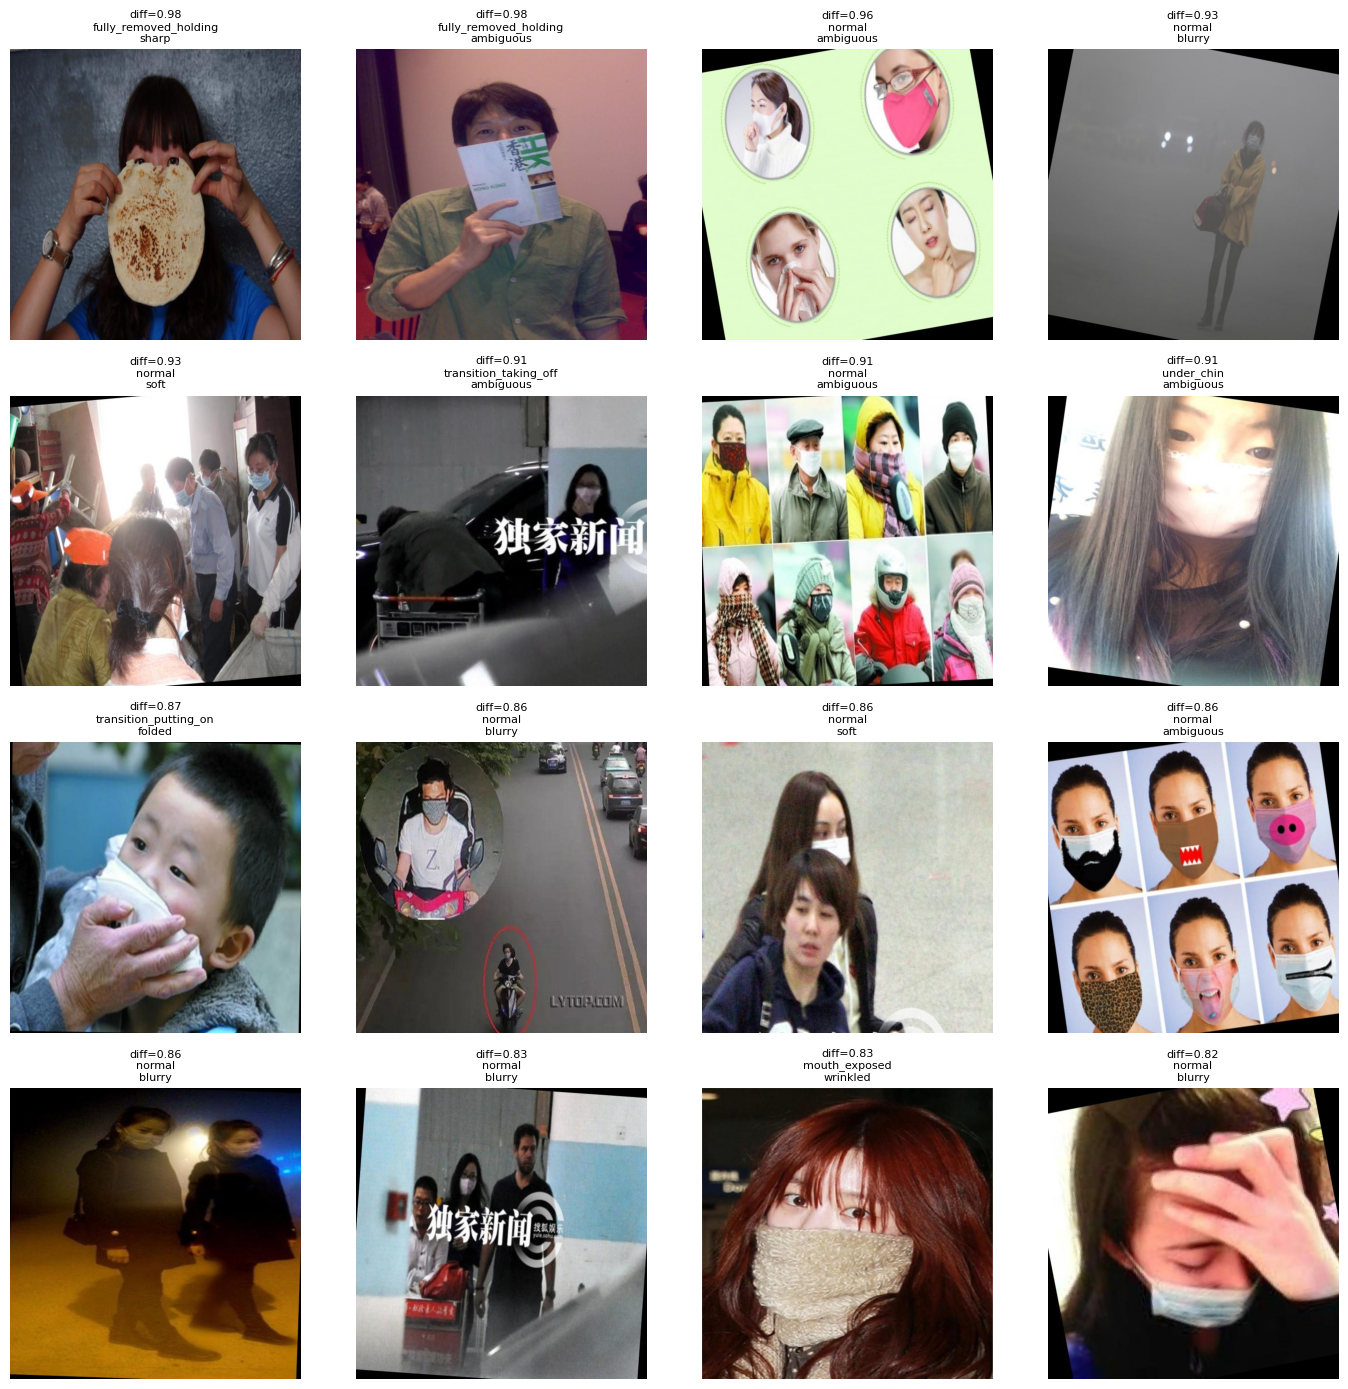

In [13]:
TOP_K = 16

samples = hard_df.head(TOP_K)

fig, axes = plt.subplots(4, 4, figsize=(14, 14))

axes = axes.flatten()

for ax, (_, row) in zip(axes, samples.iterrows()):

    image_path = row["image_path"]

    try:
        image = Image.open(image_path).convert("RGB")

        ax.imshow(image)

        title = (
            f'diff={row["segmentation_difficulty"]:.2f}\n'
            f'{row["mask_state"]}\n'
            f'{row["boundary_quality"]}'
        )

        ax.set_title(title, fontsize=8)

    except Exception as e:
        ax.text(0.5, 0.5, str(e))

    ax.axis("off")

plt.tight_layout()

plt.show()

## 특정 Edge Case만 필터링

예:

- hand overlap
- ambiguous boundary
- transition state

같은 rare sample 분석.

In [14]:
edge_df = df[
    (
        df["boundary_quality"] == "ambiguous"
    )
    &
    (
        df["segmentation_difficulty"] > 0.7
    )
]

print(edge_df.shape)

edge_df.head()

(8, 22)


,id,image_path,num_people,background,lighting,image_quality,pose,yaw,pitch,mask_state,...,deformation,occlusion_types,hand_overlap_ratio,hair_overlap_ratio,mask_visible_ratio,nose_visible_ratio,mouth_visible_ratio,chin_visible_ratio,segmentation_difficulty,difficulty_reasons
234,image_1317_jpg.rf.6bcb6c04796efad029e966ca7010...,images\image_1317_jpg.rf.6bcb6c04796efad029e96...,6,complex,"bright,cool",medium,front,0.0,0.0,normal,...,True,none,0.00,0.00,0.92,0.00,0.08,0.12,0.86,"ambiguous_boundary,deformation,partial_visibility"
239,image_1323_jpg.rf.260fbdedd9a6e3978cb86f127471...,images\image_1323_jpg.rf.260fbdedd9a6e3978cb86...,1,indoor,"dim,warm",medium,front,2.0,0.0,fully_removed_holding,...,False,"hand,object",0.18,0.00,0.00,0.00,0.00,0.00,0.98,"partial_visibility,multiple_occlusion,ambiguou..."
292,image_1400_jpg.rf.17d3a2139379a8855ef838417c50...,images\image_1400_jpg.rf.17d3a2139379a8855ef83...,1,plain,"bright,uneven",medium,tilted,-12.0,-8.0,normal,...,False,hair,0.00,0.34,0.72,0.00,0.00,0.00,0.71,"hair_overlap,ambiguous_boundary,partial_visibi..."
435,image_1605_jpg.rf.114f258a742af96152188378a4c1...,images\image_1605_jpg.rf.114f258a742af96152188...,1,indoor,"bright,uneven,backlit","medium,blurry,compressed",front,2.0,-6.0,under_chin,...,True,"hair,shadow",0.00,0.46,0.38,0.92,0.78,0.35,0.91,"hair_overlap,low_resolution,ambiguous_boundary..."
564,image_1787_jpg.rf.9f236f3f41ad6554c2f1d76b045f...,images\image_1787_jpg.rf.9f236f3f41ad6554c2f1d...,8,crowd,"bright,cool",medium,front,0.0,0.0,normal,...,True,"clothing,object",0.00,0.00,0.72,0.00,0.00,0.86,0.91,"partial_visibility,multiple_occlusion,ambiguou..."


## Edge Case Grid

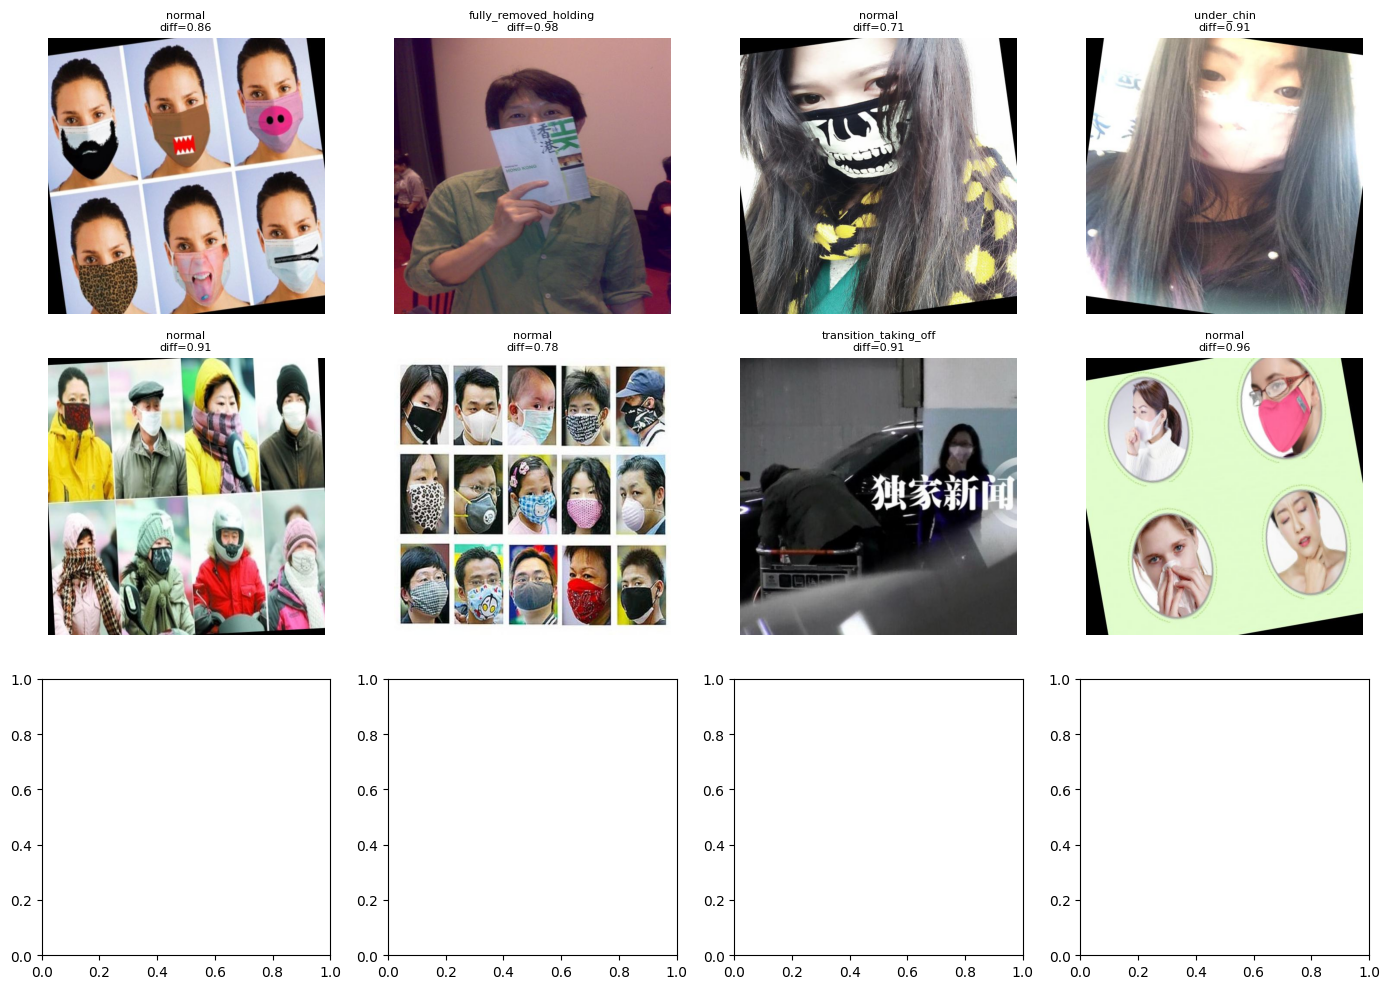

In [15]:
TOP_K = 12

samples = edge_df.head(TOP_K)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

axes = axes.flatten()

for ax, (_, row) in zip(axes, samples.iterrows()):

    try:
        image = Image.open(row["image_path"]).convert("RGB")

        ax.imshow(image)

        title = (
            f'{row["mask_state"]}\n'
            f'diff={row["segmentation_difficulty"]:.2f}'
        )

        ax.set_title(title, fontsize=8)

    except Exception as e:
        ax.text(0.5, 0.5, str(e))

    ax.axis("off")

plt.tight_layout()

plt.show()

## Annotation 품질 검증

LLM hallucination 체크용.

random sample inspection.

In [17]:
random_df = df.sample(20, random_state=42)

random_df[[
    "mask_state",
    "boundary_quality",
    "segmentation_difficulty",
    "yaw",
    "pitch",
    "occlusion_types"
]]

,mask_state,boundary_quality,segmentation_difficulty,yaw,pitch,occlusion_types
595,normal,wrinkled,0.28,-8.0,-12.0,none
587,normal,wrinkled,0.28,-12.0,-8.0,hair
543,normal,folded,0.39,-12.0,-8.0,"hair,hand"
644,normal,sharp,0.12,0.0,0.0,none
487,normal,soft,0.34,-12.0,-18.0,none
211,normal,soft,0.28,-18.0,12.0,hair
388,normal,folded,0.56,0.0,0.0,hair
527,normal,wrinkled,0.28,-5.0,-8.0,hair
244,normal,folded,0.34,68.0,2.0,none
582,normal,sharp,0.22,-8.0,22.0,none


In [18]:

df["mask_state"].value_counts()


mask_state
normal                    697
nose_exposed               31
under_chin                 18
transition_putting_on      15
transition_taking_off       6
mouth_exposed               5
covering_one_side_only      4
fully_removed_holding       3
partial_removed             1
Name: count, dtype: int64

In [19]:

(
    df["mask_state"]
    .value_counts(normalize=True)
    * 100
).round(2)


mask_state
normal                    89.36
nose_exposed               3.97
under_chin                 2.31
transition_putting_on      1.92
transition_taking_off      0.77
mouth_exposed              0.64
covering_one_side_only     0.51
fully_removed_holding      0.38
partial_removed            0.13
Name: proportion, dtype: float64